# 2-D Integrator — SD-DPC workflow

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SOLARIS-JHU/SD-DPC/blob/main/case_studies/DoubleIntegrator/notebooks/00_colab_workflow.ipynb)


## For Colab, run this cell.


In [ ]:
import sys
!if [ -d /content/SD-DPC/.git ]; then echo "[1/3] Using existing checkout: /content/SD-DPC"; else echo "[1/3] Cloning SD-DPC..."; git clone --depth 1 --progress https://github.com/SOLARIS-JHU/SD-DPC.git /content/SD-DPC; fi
%cd /content/SD-DPC

# Neuromancer 1.5.3 pins NumPy 1.26, which has no Python 3.13 wheel.
# Keep Colab's compatible NumPy, pandas, and PyTorch, and install the remaining runtime packages.
print('[2/3] Installing Colab-compatible runtime dependencies...')
%pip install --progress-bar on --no-deps neuromancer==1.5.3
%pip install --progress-bar on dill graphviz mlflow "networkx==3.0.0" "plum-dispatch==1.7.3" scikit-learn scipy six "pydot==1.4.2" pyts torchdiffeq toml lightning cvxpy "casadi>=3.7.0" wandb torchsde PyYAML seaborn

print('[3/3] Installing SD-DPC in editable mode...')
%pip install --progress-bar on --no-deps -e .

# Legacy editable installs may require exposing src/ to the current Colab kernel explicitly.
src_dir = '/content/SD-DPC/src'
if src_dir not in sys.path:
    sys.path.insert(0, src_dir)

import casadi
import neuromancer
import sdpc
import torch
print(f'Ready: SD-DPC | Python {sys.version.split()[0]} | PyTorch {torch.__version__} | Neuromancer {neuromancer.__version__}')


## Workflow options

The default configuration uses the pretrained system-identification and sparse-policy checkpoints, so the complete analysis can run without retraining. Set either training switch below to `True` to retrain that stage with the case YAML configuration. A newly trained system model is passed directly to policy training, and a newly trained policy is passed to evaluation.

Each stage begins with only the inputs it uses. Section 1 controls system-identification training; Section 2 controls policy training and the nominal rollout; Section 3 controls the evaluation scenario count and controller methods. The 2-D integrator rollout also exposes every ellipse parameter.

### Case study dynamics

The obstacle-avoidance plant is a discrete two-dimensional integrator,

$$
x_{k+1}=Ax_k+Bu_k,\qquad A=I_2,\quad B=I_2,
$$

where $x=[x_1,x_2]^\top$ is position and $u=[u_1,u_2]^\top$ is the commanded increment. The keep-out set is the interior of the rotated ellipse

$$
b\,x_r^2+y_r^2 < \left(\frac{p}{2}\right)^2,
$$

centered at $(c,d)$ and rotated by $\theta$. The controller moves between user-selected points while avoiding this set and respecting $x_i\in[-5,5]$ and $u_i\in[-1,1]$.



In [15]:
from pathlib import Path
import copy
import sys
import warnings
warnings.filterwarnings('ignore')

def find_repo_root(start=Path.cwd()):
    # This works in both a cloned Colab checkout and a local repository.
    for candidate in (start, *start.parents):
        if (candidate / 'src' / 'sdpc').is_dir() and (candidate / 'case_studies').is_dir():
            return candidate
    raise FileNotFoundError('Run this notebook from inside the SD-DPC repository')

REPO_ROOT = find_repo_root()
CASE_DIR = REPO_ROOT / 'case_studies' / 'DoubleIntegrator'
CONFIGS = CASE_DIR / 'configs'
CHECKPOINTS = CASE_DIR / 'checkpoints'
RESULTS = CASE_DIR / 'results'
sys.path.insert(0, str(REPO_ROOT / 'src'))

import matplotlib as mpl
import torch
from sdpc.config import load_config
from sdpc.registry import make_system

SYSTEM = 'double_integrator'
device = torch.device('cpu')
system = make_system(SYSTEM, device=device)
sysid_cfg = load_config(CONFIGS / 'sysid.yaml')
policy_cfg = load_config(CONFIGS / 'policy.yaml')
eval_cfg = load_config(CONFIGS / 'eval.yaml')

# Consistent notebook styling with high-resolution inline and saved figures.
mpl.rcParams.update({
    'figure.dpi': 160, 'savefig.dpi': 400,
    'font.family': 'serif', 'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],
    'mathtext.fontset': 'stix', 'axes.titlepad': 10,
})

def output_section(title):
    # Give every long-running stage an unmistakable boundary in Colab output.
    print('\n' + '─' * 78)
    print(title)
    print('─' * 78 + '\n')

print('Ready:', SYSTEM, '| case configurations loaded')


Ready: double_integrator | case configurations loaded


## 1. Sparse system identification

The dynamics are represented by a prescribed dictionary of candidate functions,

$$
\hat{x}_{k+1}=F_{\Xi_f}(x_k,u_k)=\Theta_f(x_k,u_k)\,\Xi_f.
$$

Training minimizes one-step and rollout prediction errors together with an $\ell_1$ penalty on $\Xi_f$. Sequential thresholding removes coefficients below $\tau$; the optional debias phase then fixes the surviving support, sets the sparsity penalty to zero, and refits only those coefficients.

With `TRAIN_SYSTEM_ID = False`, this section loads the pretrained dynamics checkpoint. With `True`, it trains from `sysid.yaml`, saves a numbered run, and passes the resulting model directly to policy learning. The plot compares the selected model with a held-out true trajectory.



──────────────────────────────────────────────────────────────────────────────
1 · SYSTEM IDENTIFICATION
──────────────────────────────────────────────────────────────────────────────

System ID: pretrained checkpoint
Dynamics source: /Users/alireza/Documents/PythonProject/SD-DPC/case_studies/DoubleIntegrator/checkpoints/dynamics_sindy.pt
Active terms per state: [2, 2]
dx0/dt = +1.0000e+00·x0 + +1.0000e+00·u0
dx1/dt = +1.0000e+00·x1 + +1.0000e+00·u1
Held-out rollout MSE: 1.843e-03


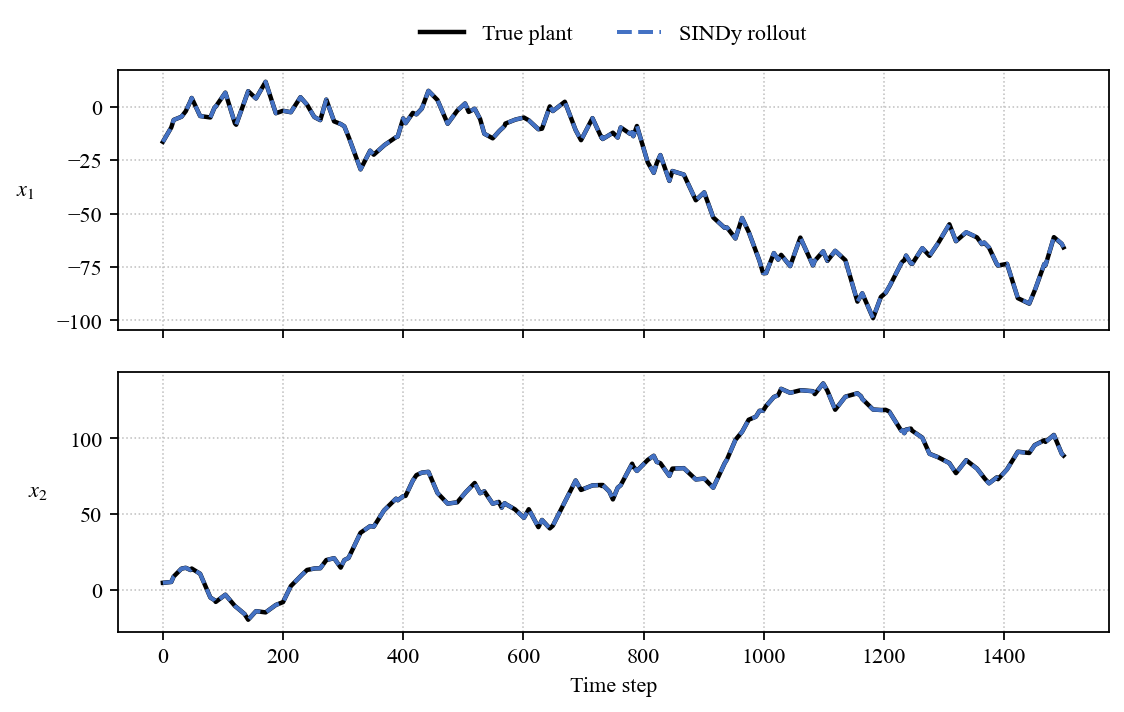

In [16]:
# ---- Section 1 inputs ---------------------------------------------------
TRAIN_SYSTEM_ID = False  # True: fit and save a new SINDy dynamics model.

output_section('1 · SYSTEM IDENTIFICATION')

print('System ID:', 'train' if TRAIN_SYSTEM_ID else 'pretrained checkpoint')

from sdpc.io import CustomLogger, new_run_dir, snapshot_config
from sdpc.plotting import plot_coef_heatmap
from sdpc.sindy import CompiledFunctionLibrary, SINDyVectorized, load_model, save_model
from sdpc.training import make_debias_config, train_sysid
import matplotlib.pyplot as plt

if TRAIN_SYSTEM_ID:
    # Build the configured dictionary and optimize all candidate coefficients.
    library = CompiledFunctionLibrary(**system.sindy_library_cfg())
    sindy = SINDyVectorized(library=library, n_out=system.nx, device=device)
    train_loader, dev_loader, test_data = system.make_sysid_data(sysid_cfg, device)
    logger = CustomLogger(
        args={'stage': 'system_id'}, savedir=str(RESULTS / 'logs' / 'sysid_colab'),
        verbosity=sysid_cfg.get('verbosity', max(1, sysid_cfg['epochs'] // 10)),
        stdout=['train_loss', 'dev_loss'],
    )
    train_sysid(system, sindy, train_loader, dev_loader, sysid_cfg, device, logger=logger)

    # Debias refits the coefficients while preserving the pruned support exactly.
    if sysid_cfg.get('debias', {}).get('enabled', False):
        support = [list(indices) for indices in sindy.active_idx]
        debias_cfg = make_debias_config(sysid_cfg)
        train_sysid(system, sindy, train_loader, dev_loader, debias_cfg, device, logger=logger)
        assert [list(indices) for indices in sindy.active_idx] == support

    dynamics_run = new_run_dir(RESULTS / 'models' / 'dynamics')
    dynamics_path = dynamics_run / 'saved_models' / 'sindy.pt'
    save_model(sindy, dynamics_path)
    snapshot_config(dynamics_run, sysid_cfg)
else:
    # Load the included pretrained dynamics model.
    dynamics_path = CHECKPOINTS / 'dynamics_sindy.pt'
    sindy = load_model(dynamics_path, device=device)
    _, _, test_data = system.make_sysid_data(sysid_cfg, device)

print('Dynamics source:', dynamics_path)
print('Active terms per state:', [len(indices) for indices in sindy.active_idx])
sindy.pretty_print()

# Compare a recursive model rollout with an unseen true-system trajectory.
step = system.discrete_step(sindy)
X_true, U_test = test_data['X'][0], test_data['u'][0]
x, prediction = X_true[:1], [X_true[:1]]
with torch.no_grad():
    for k in range(len(U_test) - 1):
        x = step(x, U_test[k:k + 1])
        prediction.append(x)
prediction = torch.cat(prediction).detach().cpu().numpy()
truth = X_true.detach().cpu().numpy()
print(f'Held-out rollout MSE: {((prediction - truth) ** 2).mean():.3e}')

fig, axes = plt.subplots(system.nx, 1, figsize=(7.2, 2.25 * system.nx), sharex=True)
axes = axes if system.nx > 1 else [axes]
for i, ax in enumerate(axes):
    ax.plot(truth[:, i], color='black', lw=2.0, label='True plant')
    ax.plot(prediction[:, i], '--', color='#4472C4', lw=1.8, label='SINDy rollout')
    ax.set_ylabel(rf'$x_{{{i + 1}}}$', rotation=0, labelpad=14)
    ax.grid(color='0.75', linestyle=':', linewidth=0.7)
axes[0].legend(frameon=False, ncol=2, loc='lower center', bbox_to_anchor=(0.5, 1.02))
axes[-1].set_xlabel('Time step')
fig.subplots_adjust(left=0.12, right=0.98, bottom=0.12, top=0.90, hspace=0.16)
plt.show()


## 2. Sparse policy learning

The controller uses a second dictionary and projects its output onto the admissible input set,

$$
u_k=\pi_{\Xi_\pi}(x_k,r_k)
=\Pi_{\mathcal U}\!\left(\Theta_\pi(x_k,r_k)\,\Xi_\pi\right).
$$

The coefficients are optimized through a differentiable closed-loop rollout of the selected dynamics model. The objective combines tracking, control effort, constraint penalties, and $\ell_1$ regularization. Sequential thresholding and fixed-support debiasing produce a compact symbolic controller.

With `TRAIN_POLICY = False`, this section loads the pretrained sparse-policy checkpoint. With `True`, it trains from `policy.yaml` using the dynamics selected above and saves a numbered run. The coefficient heatmap and nominal rollout inspect the selected policy.

### Training region

The policy training data draw initial positions from

$$
\mathcal X_0=[2,4]\times[-4,-2],
$$

and reference positions from

$$
\mathcal R=[-4,-2]\times[2,4].
$$

Samples inside the keep-out ellipse are rejected. The learned sparse policy is most reliable over these sampled regions. Initial conditions or references far outside these boxes require extrapolation and can produce poor or unsafe trajectories.




──────────────────────────────────────────────────────────────────────────────
2 · SPARSE POLICY LEARNING
──────────────────────────────────────────────────────────────────────────────

Policy: pretrained checkpoint
Training initial-state box: ((2.0, 4.0), (-4.0, -2.0))
Training reference box: ((-4.0, -2.0), (2.0, 4.0))
Rollout: x0=[3.0, -3.0], reference=[-3.0, 3.0], steps=100
Policy source: /Users/alireza/Documents/PythonProject/SD-DPC/case_studies/DoubleIntegrator/checkpoints/policy_sparse.pt
Active terms per output: [8, 4]
Total active terms: 12
u0 = +2.3984e-02·r1 + -7.8894e-03·x1^2 + -2.4915e-02·x0*r1 + +2.3433e-02·x1*r0 + +9.5105e-03·sin(1·x0) + +9.4497e-03·sin(2·x0) + +2.6654e-02·cos(1·x1) + -1.8504e-02·sin(1·r1)
u1 = +1.1061e-02·x0 + -1.4201e-02·x1 + -6.6570e-03·r0 + +1.9847e-02·r1


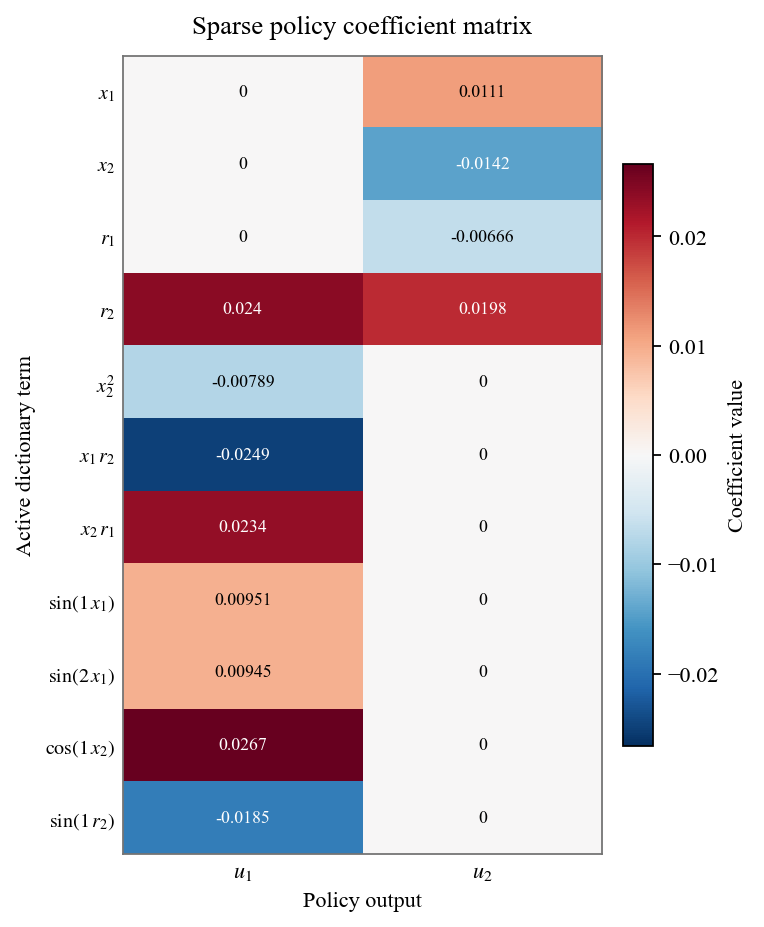

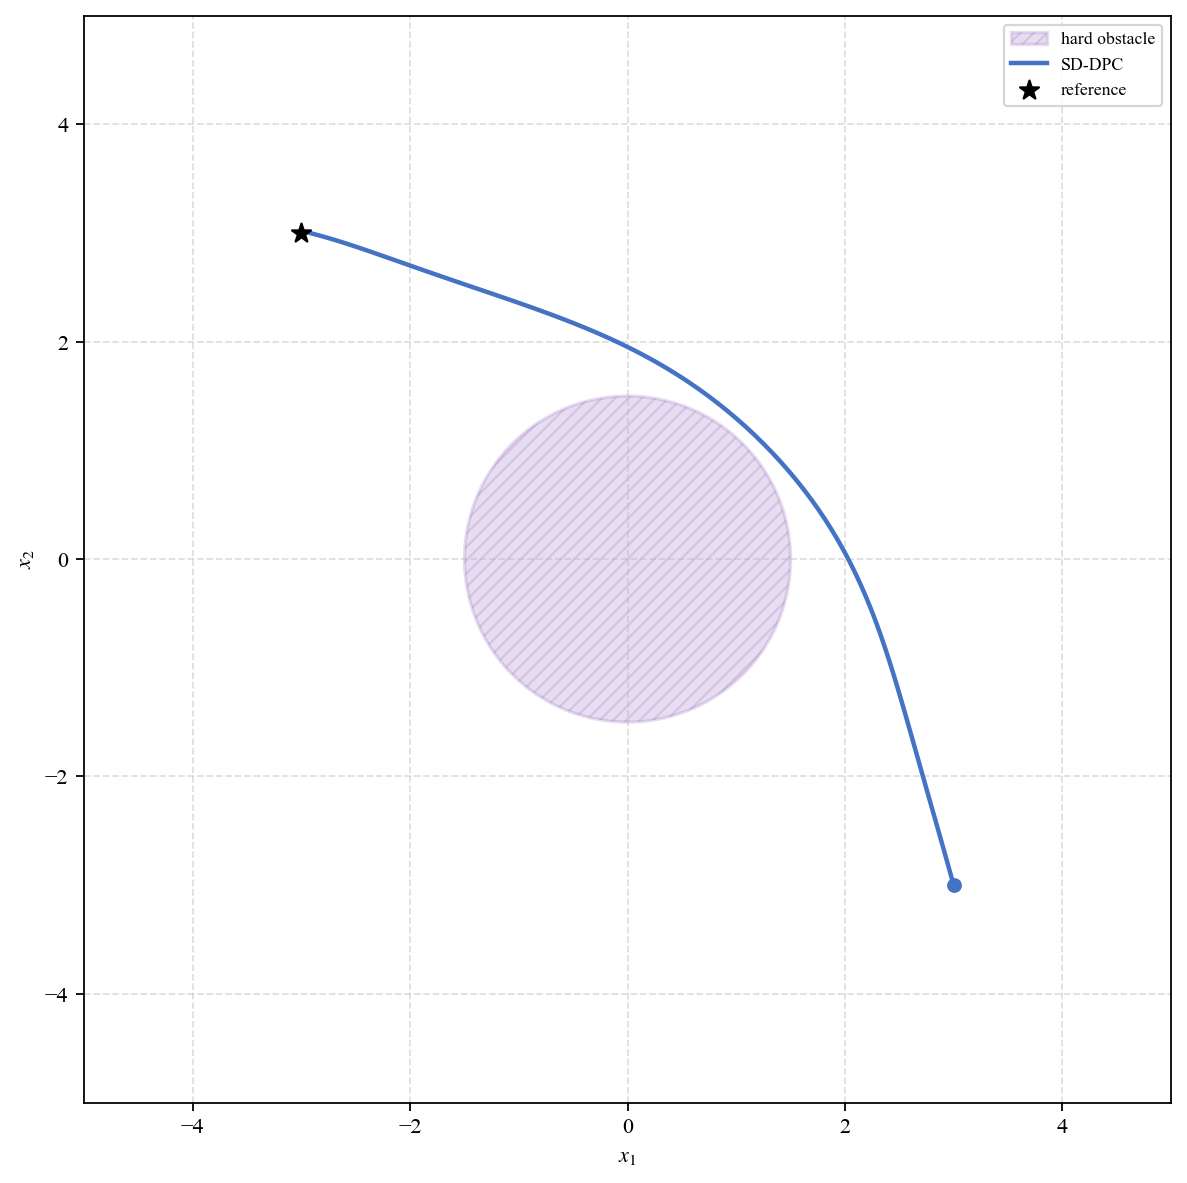

Initial state: [3.0, -3.0] | final state: [-2.9502758979797363, 3.0068535804748535]


In [17]:
# ---- Section 2 inputs ---------------------------------------------------
TRAIN_POLICY = False  # True: train against the dynamics selected in Section 1.
ROLLOUT_X0 = [3.0, -3.0]  # One value per state.
ROLLOUT_REFERENCE = [-3.0, 3.0]
ROLLOUT_STEPS = 100


# Policy-training support, computed from policy.yaml.
def square_bounds(center, side):
    half = 0.5 * float(side)
    return tuple((float(value) - half, float(value) + half) for value in center)

TRAINING_INITIAL_BOX = square_bounds(policy_cfg['init_center'], policy_cfg['init_side'])
TRAINING_REFERENCE_BOX = square_bounds(policy_cfg['ref_center'], policy_cfg['ref_side'])

def inside_box(point, bounds):
    return all(lower <= float(value) <= upper for value, (lower, upper) in zip(point, bounds))

# Ellipse geometry: size p, aspect b, center (c, d), and rotation theta.
ROLLOUT_OBSTACLE = dict(policy_cfg['ellipse'])

if len(ROLLOUT_X0) != system.nx or len(ROLLOUT_REFERENCE) != system.nx:
    raise ValueError(f'Initial condition and reference must each have {system.nx} entries')
if ROLLOUT_STEPS < 1:
    raise ValueError('ROLLOUT_STEPS must be positive')

if not inside_box(ROLLOUT_X0, TRAINING_INITIAL_BOX):
    warnings.warn(
        f'ROLLOUT_X0={ROLLOUT_X0} is outside the training box {TRAINING_INITIAL_BOX}; '
        'the policy is extrapolating and may produce a poor trajectory.',
        stacklevel=2,
    )
if not inside_box(ROLLOUT_REFERENCE, TRAINING_REFERENCE_BOX):
    warnings.warn(
        f'ROLLOUT_REFERENCE={ROLLOUT_REFERENCE} is outside the training box '
        f'{TRAINING_REFERENCE_BOX}; the policy is extrapolating and may produce a poor trajectory.',
        stacklevel=2,
    )

output_section('2 · SPARSE POLICY LEARNING')

print('Policy:', 'train' if TRAIN_POLICY else 'pretrained checkpoint')
print('Training initial-state box:', TRAINING_INITIAL_BOX)
print('Training reference box:', TRAINING_REFERENCE_BOX)
print(f'Rollout: x0={ROLLOUT_X0}, reference={ROLLOUT_REFERENCE}, steps={ROLLOUT_STEPS}')

from sdpc.io import new_policy_run_dir
from sdpc.training import train_policy

if TRAIN_POLICY:
    # Optimize a symbolic policy through the differentiable identified dynamics.
    policy_library = CompiledFunctionLibrary(**system.policy_library_cfg())
    policy = SINDyVectorized(
        library=policy_library, n_out=system.nu,
        policy_name=[f'u{i}' for i in range(system.nu)],
        device=device, seed=policy_cfg.get('policy_seed', 0),
    )
    if policy_cfg.get('init_scale') is not None:
        for coefficient in policy.Xi:
            coefficient.data.mul_(policy_cfg['init_scale'])

    train_loader, dev_loader = system.make_policy_data(policy_cfg, device)
    logger = CustomLogger(
        args={'stage': 'policy'}, savedir=str(RESULTS / 'logs' / 'policy_colab'),
        verbosity=policy_cfg['verbosity'],
        stdout=policy_cfg.get('logger_metrics', ['train_loss', 'dev_loss']),
    )
    train_policy(
        system, sindy, policy, train_loader, dev_loader, policy_cfg, device,
        logger=logger, action_scale=policy_cfg.get('action_scale', 1.0),
    )

    # Keep the selected symbolic support fixed during the debias phase.
    if policy_cfg.get('debias', {}).get('enabled', False):
        support = [list(indices) for indices in policy.active_idx]
        debias_cfg = make_debias_config(policy_cfg)
        train_policy(
            system, sindy, policy, train_loader, dev_loader, debias_cfg, device,
            logger=logger, action_scale=policy_cfg.get('action_scale', 1.0),
        )
        assert [list(indices) for indices in policy.active_idx] == support

    policy_run = new_policy_run_dir(RESULTS, 'sparse')
    policy_path = policy_run / 'saved_models' / 'policy_sparse.pt'
    save_model(policy, policy_path)
    snapshot_config(policy_run, policy_cfg)
else:
    policy_path = CHECKPOINTS / 'policy_sparse.pt'
    policy = load_model(policy_path, device=device)

policy.eval()
print('Policy source:', policy_path)
print('Active terms per output:', [len(indices) for indices in policy.active_idx])
print('Total active terms:', sum(len(indices) for indices in policy.active_idx))
policy.pretty_print()

# The annotated matrix shows the exact retained symbolic policy parameters.
plot_coef_heatmap(policy, title='Sparse policy coefficient matrix', annotate=True)
plt.show()

from sdpc.eval import make_test_data, rollout_closed_loop
nominal_plant = system.discrete_step(sindy)
data = make_test_data(
    system.nx, ROLLOUT_STEPS, ROLLOUT_X0, ROLLOUT_REFERENCE, device=device,
)
result = rollout_closed_loop(
    policy, nominal_plant, data, umin=system.umin, umax=system.umax,
    action_scale=policy_cfg.get('action_scale', 1.0),
)
from sdpc.plotting import plot_trajectories_with_ellipse

# Draw the user-selected keep-out ellipse and the resulting state-space path.
ellipse = ROLLOUT_OBSTACLE
plot_trajectories_with_ellipse(
    [{'traj': result['x_traj'], 'label': 'SD-DPC', 'color': '#4472C4'}],
    r=data['r'], p=ellipse['p'], b=ellipse['b'], c=ellipse['c'], d=ellipse['d'],
    theta=ellipse.get('theta', 0.0), xmin=system.xmin, xmax=system.xmax,
    title='',
)
plt.show()
print('Initial state:', data['xn'][0, 0].tolist(), '| final state:', result['x_traj'][0, -1].tolist())


## 3. Closed-loop evaluation

Evaluation applies each selected controller to the same true-plant scenarios. Edit `EVAL_SCENARIOS` to control the Monte Carlo sample count, `EVAL_HORIZON` to choose the simulated time-step horizon, and `EVAL_INITIAL_STATE` to use the same fixed start in every scenario. Leave `EVAL_INITIAL_STATE = None` for a different seeded start in every scenario. Select any supported subset in `EVAL_METHODS`: `sd_dpc`, `nn_dpc`, and `mpc`. The default settings remain in the YAML file and are copied before the notebook applies these interactive choices.

The tables report tracking, constraint, control-effort, and timing metrics on matched initial conditions and references. The plotted scenario uses the same data for every selected method, making differences in the closed-loop trajectories directly comparable.
For this case, a fixed `EVAL_INITIAL_STATE` should normally remain in $[2,4]\times[-4,-2]$. Starts far outside this training box test policy extrapolation and may yield poor trajectories. Random starts generated with `EVAL_INITIAL_STATE = None` use the configured training-side box.



In [18]:
# ---- Section 3 inputs ---------------------------------------------------
EVAL_SCENARIOS = 10.0
EVAL_METHODS = ['sd_dpc', 'nn_dpc', 'mpc']  # Remove any method you do not want to run.
EVAL_INITIAL_STATE = None  # None: random starts; e.g. [3.0, -3.0] for an in-distribution fixed start.
EVAL_HORIZON = int(eval_cfg.get('eval_nsteps', eval_cfg.get('nsteps', 100)))

if EVAL_SCENARIOS < 1 or EVAL_HORIZON < 1 or not EVAL_METHODS:
    raise ValueError('EVAL_SCENARIOS and EVAL_HORIZON must be positive; EVAL_METHODS cannot be empty')
if EVAL_INITIAL_STATE is not None and len(EVAL_INITIAL_STATE) != system.nx:
    raise ValueError(f'EVAL_INITIAL_STATE must contain {system.nx} values')
if EVAL_INITIAL_STATE is not None and not inside_box(EVAL_INITIAL_STATE, TRAINING_INITIAL_BOX):
    warnings.warn(
        f'EVAL_INITIAL_STATE={EVAL_INITIAL_STATE} is outside the training box '
        f'{TRAINING_INITIAL_BOX}; SD-DPC and NN-DPC are extrapolating.',
        stacklevel=2,
    )

output_section('3 · CLOSED-LOOP EVALUATION')

print(f'Evaluation: {EVAL_SCENARIOS} scenarios, horizon={EVAL_HORIZON}, methods={EVAL_METHODS}')
print('Initial state:', EVAL_INITIAL_STATE if EVAL_INITIAL_STATE is not None else 'random per scenario')

# Copy the evaluation configuration before applying the user-selected controls.
evaluation_cfg = copy.deepcopy(eval_cfg)
evaluation_cfg.pop('seeds', None)
evaluation_cfg['n_seeds'] = int(EVAL_SCENARIOS)
evaluation_cfg['methods'] = list(EVAL_METHODS)
evaluation_cfg['eval_nsteps'] = int(EVAL_HORIZON)
evaluation_cfg['initial_state'] = EVAL_INITIAL_STATE
allowed_methods = {'sd_dpc', 'nn_dpc', 'mpc'}
unknown_methods = sorted(set(EVAL_METHODS) - allowed_methods)
if unknown_methods:
    raise ValueError(f'Unknown methods: {unknown_methods}; choose from {sorted(allowed_methods)}')

from sdpc.io import find_nn_checkpoint
from sdpc.training import load_nn_policy

# Load the neural baseline only when it is part of this comparison.
nn_policy = None
if 'nn_dpc' in EVAL_METHODS:
    nn_path = find_nn_checkpoint(RESULTS, evaluation_cfg)
    nn_policy = load_nn_policy(system, nn_path, evaluation_cfg, device=device)

from sdpc.eval import dpc_loss_reference, evaluate
from sdpc.plotting import format_metrics_table, plot_trajectories_with_obstacles

out_dir = RESULTS / 'eval' / 'controller_comparison'
print('Loss reference:', dpc_loss_reference(system, evaluation_cfg))
out = evaluate(
    system, sindy, policy, evaluation_cfg, device,
    out_dir=out_dir, nn_policy=nn_policy,
)
print(format_metrics_table(out['summary']))



──────────────────────────────────────────────────────────────────────────────
3 · CLOSED-LOOP EVALUATION
──────────────────────────────────────────────────────────────────────────────

Evaluation: 10.0 scenarios, horizon=100, methods=['sd_dpc', 'nn_dpc', 'mpc']
Initial state: random per scenario
Loss reference: {'horizon': 100, 'refstep': 1, 'weights': {'Q_r': 1.0, 'Q_u': 10.0, 'Q_uf': 5.0, 'Q_dx': 1.0, 'Q_du': 10.0, 'Q_con_obs': 100.0, 'Q_con_x': 1.0, 'Q_con_u': 1.0}, 'objectives': ['terminal_tracking', 'control_effort', 'state_smoothing', 'control_smoothing', 'terminal_control'], 'constraints': ['rotated_ellipse', 'state_box', 'control_box'], 'policy_only': ['action_at_reference', 'l1_sparsity'], 'mpc_excluded_policy_only': ['action_at_reference', 'l1_sparsity'], 'mpc_horizon': 100}
method           | final_tracking_mse | steps_to_reach   | total_control_action_l1 | control_smoothness_rms | num_violations   | min_safety_margin | policy_forward_per_step_ms | sparsity_total_terms
---

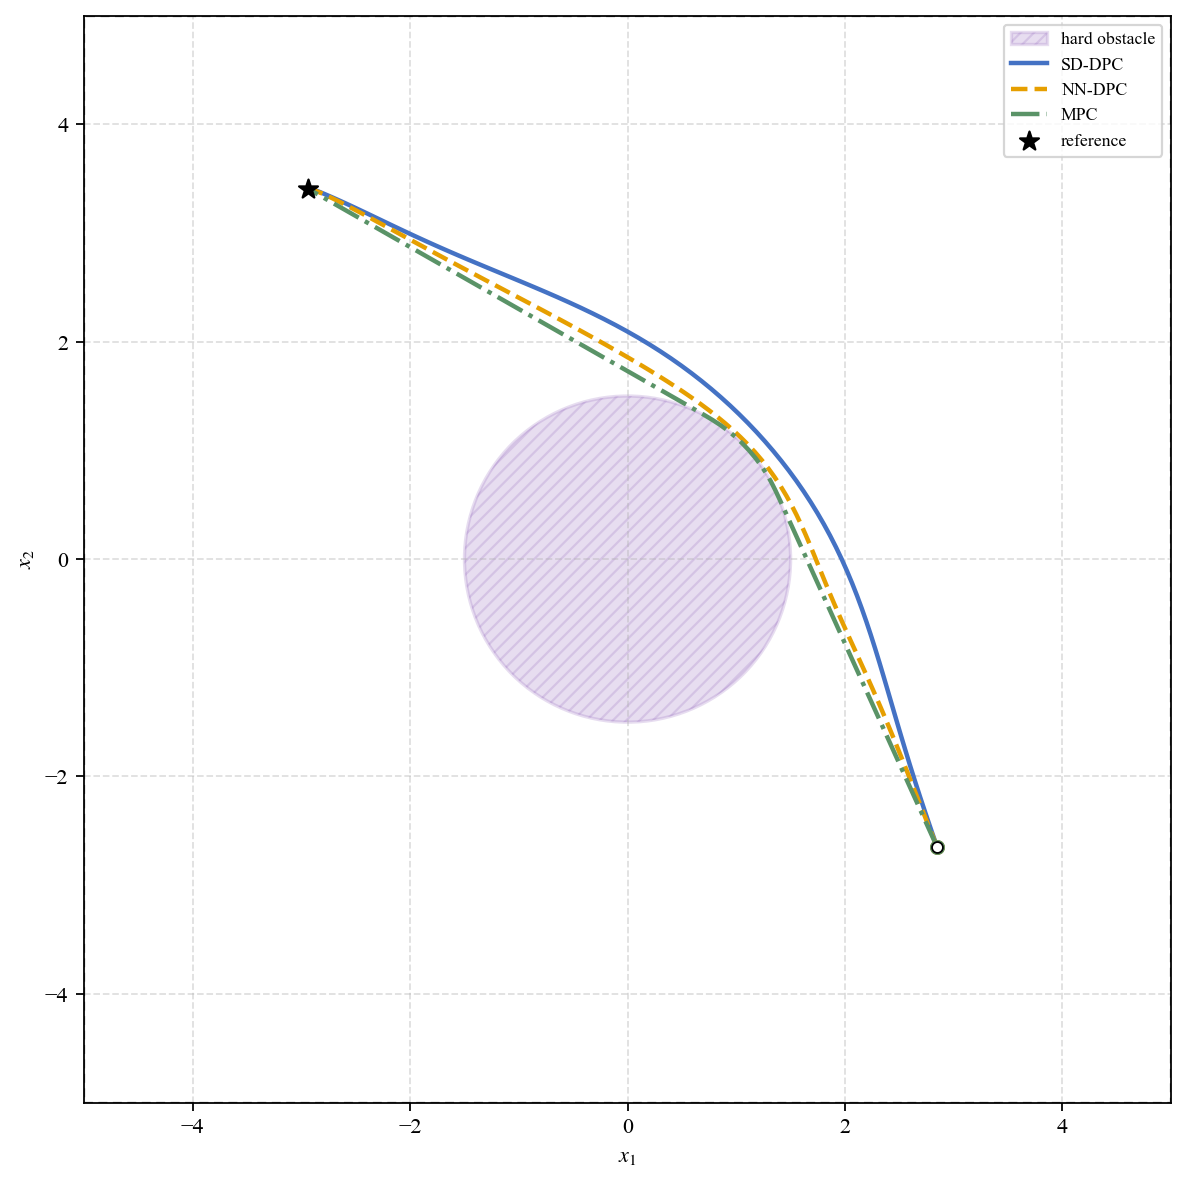

In [19]:
index = 6
scenario = out['scenarios'][index]
styles = {
    'mpc': ('MPC', '#5A9367', '-.'),
    'sd_dpc': ('SD-DPC', '#4472C4', '-'),
    'nn_dpc': ('NN-DPC', '#E69F00', '--'),
}
trajectories = [
    {
        'traj': out['trajectories'][name]['x_traj'][index:index + 1],
        'label': styles[name][0], 'color': styles[name][1], 'linestyle': styles[name][2],
    }
    for name in EVAL_METHODS
]
plot_trajectories_with_obstacles(
    trajectories, [evaluation_cfg['ellipse']], scenario['r'], obstacle_band=0.0,
    xmin=system.xmin, xmax=system.xmax, state_bounds=(system.xmin, system.xmax),
    show_initial=True, title='',
)
plt.show()